## Import Libreries

In [0]:
%pip install seaborn wordcloud

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from wordcloud import WordCloud

### Load the DataSet

In [0]:
df = pd.read_csv("/Workspace/Users/soumyanalyst323@gmail.com/Netflix EDA Analysis/netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [0]:
# Get the concise summary of the dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


- **Insights:** We have have 8807 entities.
-  Any column less than 8807 entites contains missing values ['director', 'cast', 'country', 'date_added','rating', 'duration'].
-  Data type inconsistency in date_added column. It should be of datetime type but currently it should have object type.
-  Number features 12.

### **Data Cleaning & Transformation:**

In [0]:
# Check the null values 
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [0]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [0]:
# handle the missing values Director and cast column
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')

In [0]:
# Handel the country column
mode_country = df['country'].mode()[0]
df['country'] = df['country'].fillna(mode_country)

In [0]:
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
dtype: int64

In [0]:
# Handel 'date_aded', 'rating', 'duration'.
# Drop the few rows with missing 
df.dropna(subset=['date_added', 'duration','rating'], inplace= True)

In [0]:
# Check again all null values
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [0]:
df.shape

(8790, 12)

### Data type inconsistency in 'date_added' column 

In [0]:
df['date_added']  = pd.to_datetime(df['date_added'], format='mixed', dayfirst= False)

### Feature Engineering

In [0]:
# Create new features for year and month added
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month

In [0]:
# Verify our cleaning and transformation
print('Missing Values After Cleaning')
print(df.isnull().sum())
print('\nData types after transformation')
print(df.dtypes)

Missing Values After Cleaning
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
year_added      0
month_added     0
dtype: int64

Data types after transformation
show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
year_added               int32
month_added              int32
dtype: object


In [0]:
# convert into new datframe
clean_data = df.copy()
# Save the cleaned data to a new CSV file
clean_data.to_csv('/Volumes/workspace/default/eda/clean_data.csv')

### **EDA: Exploratory Data Analysis**
- **Univariate Analysis : Only one variable/ feature at a time**

In [0]:
clean_data.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'year_added', 'month_added'],
      dtype='object')

### Disdtibution of content type

In [0]:
# Distribution of content type
type_counts = clean_data['type'].value_counts()
print(type_counts)


type
Movie      6126
TV Show    2664
Name: count, dtype: int64


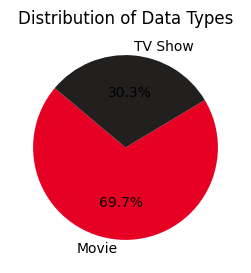

In [0]:
# Visualize the pie chart
plt.figure(figsize=(5, 3))
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=140, colors=['#e60023', '#221f1f'])
plt.title('Distribution of Data Types')
plt.show()

#### Insights: 
- The NEtflix librery is highly dominated by Movies.
- Which is make up roughly 70% fo the content specifically.

###  01. How has the content addded over the time?

In [0]:
# how has the content addded over the time?
content_over_time = clean_data.groupby(['year_added', 'type']).size().unstack().fillna(0)
print(content_over_time)

type         Movie  TV Show
year_added                 
2008           1.0      1.0
2009           2.0      0.0
2010           1.0      0.0
2011          13.0      0.0
2012           3.0      0.0
2013           6.0      5.0
2014          19.0      5.0
2015          56.0     26.0
2016         251.0    175.0
2017         836.0    349.0
2018        1237.0    411.0
2019        1424.0    592.0
2020        1284.0    595.0
2021         993.0    505.0


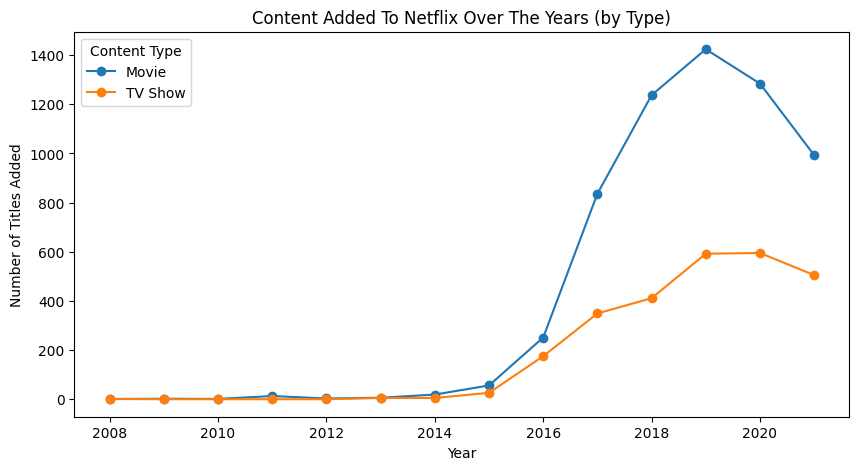

In [0]:
# Create the line chart
content_over_time.plot(kind='line', figsize=(10, 5), marker = 'o')
plt.title('Content Added To Netflix Over The Years (by Type)')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')
plt.legend(title='Content Type')
plt.show()
#

#### Insights: 
- By separating movies and TV shows, we can clearly see that while both grow significantly from the year 2008 to 2020,
- the addition of movies accelarated more dramatically, especially in the year 2019.
- The growth in the Tv Shows has been more steady. There appears to be slight shot down in content addition 
- in the year 2020 and 2021. which colud be due to the peak of covid-19 at that time which might affects the 
- poducttions or maybe the dataset colud be incomplete for the latest year.


### 02. What are the popular Genre?

In [0]:
clean_data.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'year_added', 'month_added'],
      dtype='object')

In [0]:
# Split the 'listed_in' column and explode it
genres = clean_data.assign(genre = clean_data['listed_in'].str.split(', ')).explode('genre')
genres

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,genre
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,9,Documentaries
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,International TV Shows
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,TV Dramas
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,9,TV Mysteries
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,9,Crime TV Shows
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020,1,Children & Family Movies
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020,1,Comedies
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...,2019,3,Dramas
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...,2019,3,International Movies


#### Most popular genres

In [0]:
# Get the top 15 genres and their counts
top_genres_count = genres['genre'].value_counts().reset_index()

# Rename columns for clarity
top_genres_count.columns = ['genre', 'count']

# Select only the top 15  for ploting
top_genre_counts_plot =  top_genres_count.head(15)
top_genre_counts_plot

,genre,count
0,International Movies,2752
1,Dramas,2426
2,Comedies,1674
3,International TV Shows,1349
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,762
7,Independent Movies,756
8,Children & Family Movies,641
9,Romantic Movies,616


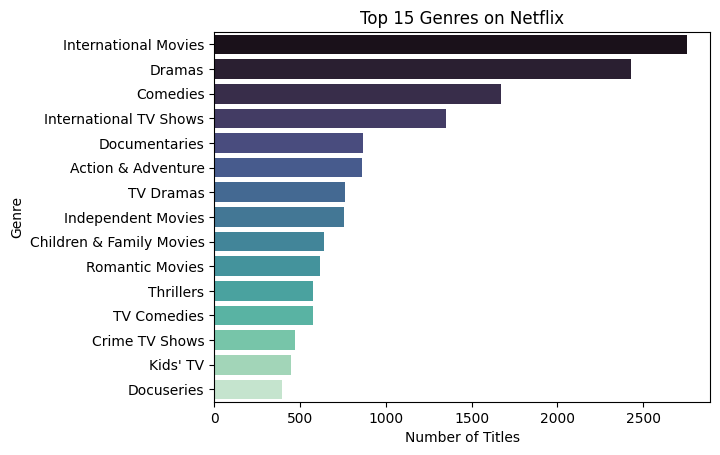

In [0]:
# Visulaize the data in bar chart
sns.barplot(y = 'genre', x = 'count', data =top_genre_counts_plot, palette='mako', hue = 'genre', legend=False)
plt.title('Top 15 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

### Insights:
- International Movies is the most common genre highlighting the Netflix global content strategy.

### Distribution of Content duration

In [0]:
# Separate movies and Tv shows
movies_df = clean_data[clean_data['type'] == 'Movie'].copy()
tv_shows_df = clean_data[clean_data['type'] == 'TV Show'].copy()


In [0]:
movies_df.sample(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
5016,s5017,Movie,Trailer Park Boys Live at the North Pole,"Mike Smith, John Paul Tremblay, Robb Wells","Mike Smith, John Paul Tremblay, Robb Wells, Jo...",Canada,2018-03-01,2014,TV-MA,89 min,Movies,Bubbles's plan to spread the true meaning of C...,2018,3
175,s176,Movie,The Blue Lagoon,Randal Kleiser,"Brooke Shields, Christopher Atkins, Leo McKern...",United States,2021-09-01,1980,R,105 min,"Dramas, Romantic Movies","Two shipwrecked children, stranded for years o...",2021,9
1734,s1735,Movie,Midnight at the Magnolia,Maxwell McGuire,"Natalie Hall, Evan Williams, Michael Gordon Sh...",Canada,2020-11-05,2020,TV-G,87 min,"Comedies, Romantic Movies",Longtime friends and local radio hosts Maggie ...,2020,11


In [0]:
tv_shows_df.sample(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
1152,s1153,TV Show,Rainbow High,Unknown,"Tara Sands, Anairis Quiñones, Laura Stahl, Jen...",United States,2021-03-30,2020,TV-Y,1 Season,Kids' TV,The popular fashion dolls come to life in this...,2021,3
39,s40,TV Show,Chhota Bheem,Unknown,"Vatsal Dubey, Julie Tejwani, Rupa Bhimani, Jig...",India,2021-09-16,2021,TV-Y7,3 Seasons,Kids' TV,"A brave, energetic little boy with superhuman ...",2021,9
6294,s6295,TV Show,Bh Se Bhade,Unknown,"Deven Bhojani, Suchita Trivedi, Sarita Joshi, ...",India,2018-04-01,2013,TV-PG,1 Season,"International TV Shows, TV Comedies",A kind-hearted insurance agent has the mysteri...,2018,4


In [0]:
# Clean and convert duration for movies
movies_df['duration_min'] = movies_df['duration'].str.replace(' min', '').astype(int)

# Clean and convert duration for TV shows
tv_shows_df['seasons'] = tv_shows_df['duration'].str.replace(' Seasons', '').str.replace(' Season', '').astype(int)

/home/spark-58a43f16-c3c8-4e27-816f-74/.ipykernel/65/command-8044372831661281-1279835388:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = tv_shows_df, x = 'seasons', ax=axes[1], palette='rocket', order=tv_shows_df['seasons'].value_counts().index)


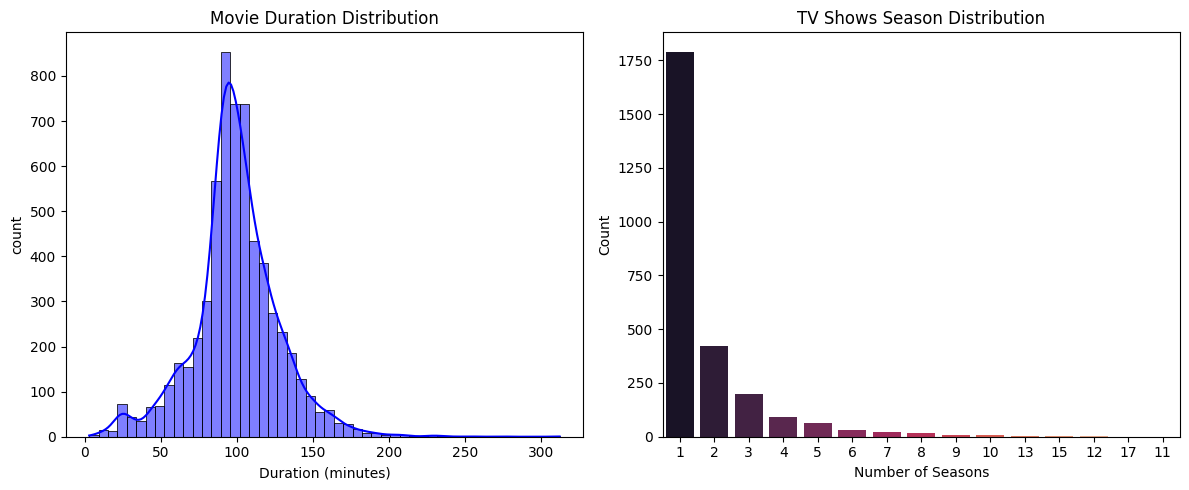

In [0]:
# # Plot the distribution 
fig , axes = plt.subplots(1, 2, figsize=(12, 5))
# Movie duration distribution
sns.histplot(data = movies_df, bins=50, kde=True, ax=axes[0], x = 'duration_min', color='blue')
axes[0].set_xlabel('Duration (minutes)')
axes[0].set_ylabel('count')
axes[0].set_title('Movie Duration Distribution')

# TV Shows sesson distribution
sns.countplot(data = tv_shows_df, x = 'seasons', ax=axes[1], palette='rocket', order=tv_shows_df['seasons'].value_counts().index)
axes[1].set_xlabel('Number of Seasons')
axes[1].set_ylabel('Count')
axes[1].set_title('TV Shows Season Distribution')
plt.tight_layout()
plt.show()

### Insights: 
- The majority of the movies on Netflix are in the range between 80 and 120 minutes long.
- Which is ideally the standard for ant features films.

- The vast majority of Tv Shows on Netflix are short-lived, with most having only 1 season. 
-  This could also reflect a strategy of producing many plots  and only reviewing the most successfull ones. or a focus on a lmiited series.

#### Where does the content come from? 

In [0]:
clean_data.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'year_added', 'month_added'],
      dtype='object')

In [0]:
# Handel the multi-country listing similar to genre
countries = clean_data.assign(country = clean_data['country'].str.split(', ')).explode('country')

# Get the top 15 countries and thier counts
top_countries_counts = countries['country'].value_counts().reset_index()
top_countries_counts.columns = ['country', 'count']
print(top_countries_counts.head(15))

           country  count
0    United States   4509
1            India   1046
2   United Kingdom    803
3           Canada    445
4           France    393
5            Japan    316
6            Spain    232
7      South Korea    231
8          Germany    226
9           Mexico    169
10           China    162
11       Australia    158
12           Egypt    117
13          Turkey    113
14       Hong Kong    105


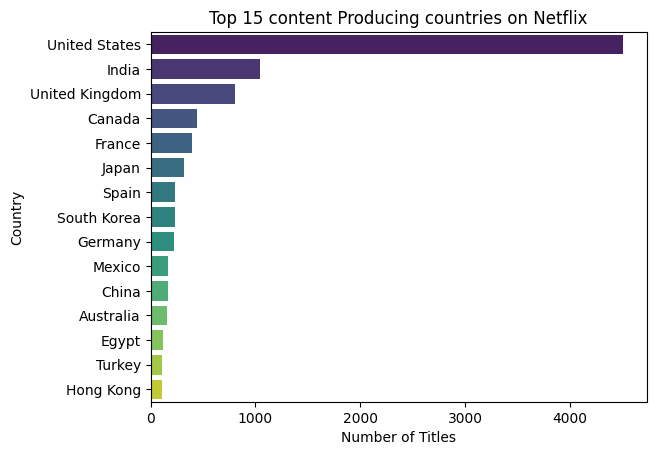

In [0]:
# select only the top 15 countries
top_countries = top_countries_counts.head(15)

sns.barplot(y = 'country', x = 'count', data = top_countries, palette='viridis', hue = 'country', legend = False)
plt.title('Top 15 content Producing countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

### Insights:
- The US is by far the largest producer of the content available on Netflix followed by India which somehow explains that why so many top actors were from India.

#### Maturity ratings of the Content

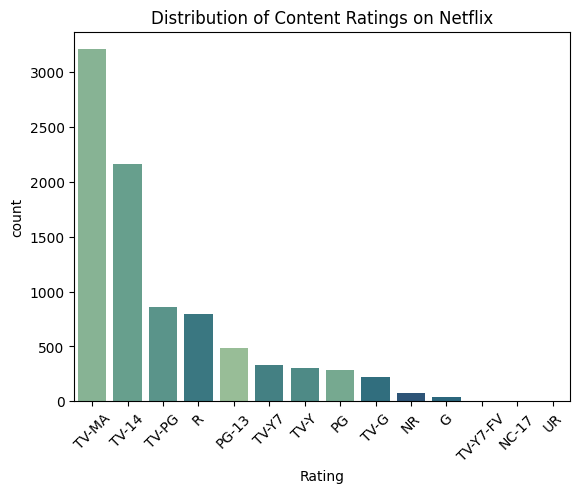

In [0]:
sns.countplot(x = 'rating', data = clean_data, order=clean_data['rating'].value_counts().index, palette='crest', hue = 'rating')
plt.title('Distribution of Content Ratings on Netflix')
plt.xlabel('Rating')
plt.ylabel('count')
plt.xticks(rotation = 45)
plt.show()

### Insights:
- A large portion of the Netflix content aimed at mature audiences, with TV-MA(MAture audience) and TV-14 (Parents Strongly Cautioned)
- being the two most common ratings. 

In [0]:
## Feature Engineering
clean_data['age_on_netflix'] = clean_data['year_added'] - clean_data['release_year']

In [0]:
# Filter out any any potential errors where added_year is before release year
content_age  = clean_data[clean_data['age_on_netflix']>= 0]

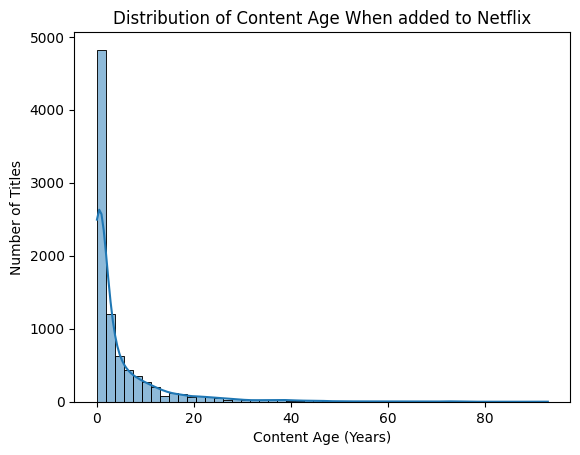

In [0]:
sns.histplot(data=content_age, x = 'age_on_netflix', bins = 50, kde= True)
plt.title('Distribution of Content Age When added to Netflix')
plt.xlabel('Content Age (Years)')
plt.ylabel('Number of Titles')
plt.show()

#### Insights:
- The large spike at 0 indicates that the significant amount of content is being added in the same year, 
- which is characterstics of the "Netflix Original". However there is a long tail, showing that Netflix also heavily invest in acquiring licensed content that can be decades old, building a library classic films and TV-Shows.

### **Multivariate Analysis:**

In [0]:
top_genres = genres['genre'].value_counts().index[:5]
genres_movies = genres[(genres['type'] == 'Movie') & (genres['genre'].isin(top_genres))].copy()
genres_movies['duration_min'] = genres_movies['duration'].str.replace(' min', '').astype(int)

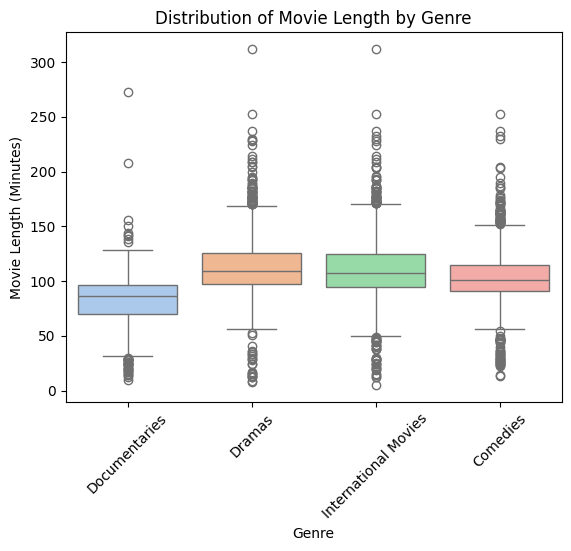

In [0]:
sns.boxplot(data = genres_movies, x = 'genre', y = 'duration_min', palette='pastel', hue = 'genre', legend = False)
plt.title('Distribution of Movie Length by Genre')
plt.xlabel('Genre')
plt.ylabel('Movie Length (Minutes)')
plt.xticks(rotation = 45)
plt.show()

#### Insights:
- Dramas & international Movies have more outliers and reflects the diverse filmmaking styles around the world.

### Word Cloud From the content description

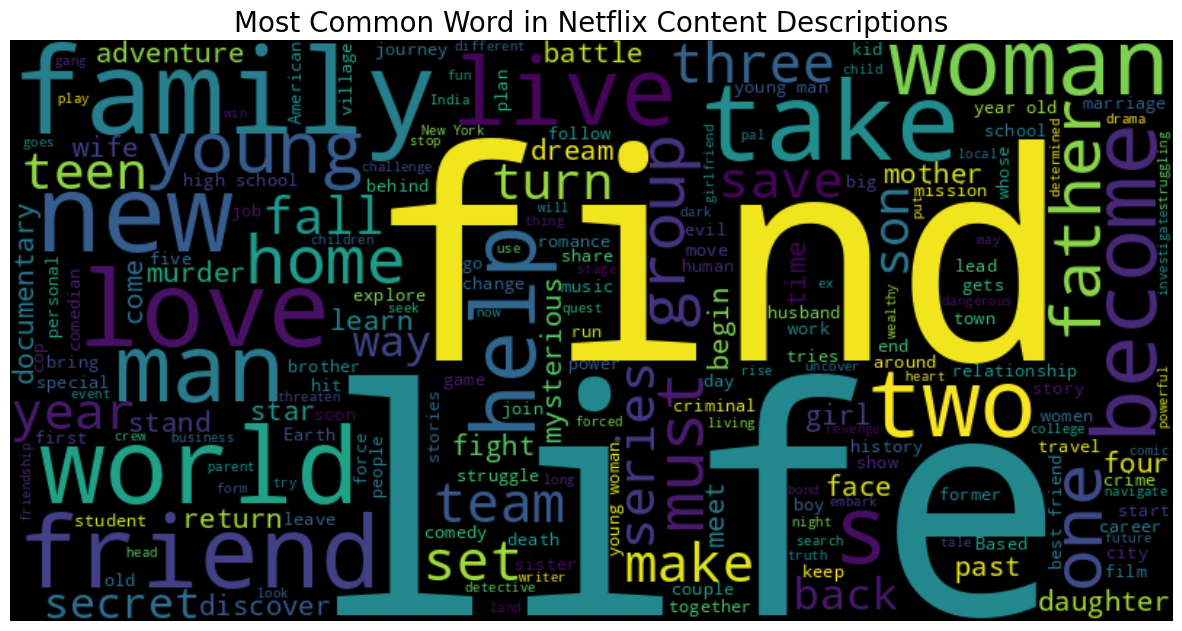

In [0]:
# Combine all description into a single string
text = ' '.join(clean_data['description'])

# Create and generate a word cloud image
wordcloud = WordCloud(width = 800, height=400, background_color='black').generate(text)

# Display the generated image
plt.figure(figsize= (15,10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title('Most Common Word in Netflix Content Descriptions', fontsize = 20)
plt.show()